# Wald test vs. parallel-curves test with and without slide effects (legnini)

Three answers to the morphogen question (Ctrl vs. SHH slides, expression along the distance to SHH+ cells), on the same gene panel and expression layer:

1. **Binned, classic Wald, no slide effects** (`test="wald"`): sliding-window bins, tradeSeq-style Wald test on the posterior-predictive curves (NUTS), p-values from the **Gamma** null fitted to the panel (`gamma_pval`).
2. **Raw cells, parallel-curves test, no slide effects** (`use_binned=False, inference="advi"`): every cell, full-rank ADVI (Laplace start, Adam polish). Cells of a condition are pooled, so the variation between slides is ignored.
3. **Raw cells, parallel-curves test with slide effects** (`bin_obs(sample="sample")`, `inference="advi"`): adds a random level and a random curve per slide. Their two scales are set by empirical Bayes (the mode of their marginal posterior, `slide_scales="empirical_bayes"`), and the p-value uses an F reference with `n_slides - 2` denominator degrees of freedom. On a within-condition split of the SHH slides (no true difference), part 2's model flagged 94% (`tau=0`) / 62% (`tau=0.1`) of genes; modelling slides brings that to the nominal level (see `.claude/advi_plan.md`).

Each part shows the ranked gene table, a p-value histogram and a volcano plot; the end compares the three rankings. Part 4 clusters the fitted curves and can run on its own after the data and settings cells.

**Before running:** all parts cover the whole 88-gene panel with 4 worker processes. Part 3 is the slowest (the slide effects add ~180 parameters per gene); shorten `GENES` for a trial run, but keep roughly 10+ genes, since the Wald test's Gamma null is fitted to the panel.

In [1]:
# One BLAS thread per process: the fits run in worker processes, and oversubscribed BLAS threads slow them down a lot.
import os

for var in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS"):
    os.environ[var] = "1"

import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import squidpy as sq

import diffsvg as dvg

/home/lehnerl/miniconda3/envs/pymc_env/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Data and anchor

As in the morphogen example: cells in the top percentile of SHH expression are the anchor, and every other cell gets its (normalised) distance to the closest SHH+ cell of its slide. The slide of each cell (`sample`) is part of the design matrix.

In [2]:
adata = sc.read_h5ad("/home/lehnerl/Arbeit/data/legnini23.h5ad")

shh = adata[:, "SHH"].X
shh = (shh.toarray() if hasattr(shh, "toarray") else np.asarray(shh)).ravel()
adata.obs["SHH+"] = (shh > np.percentile(shh, 99)).astype(str)

sq.tl.var_by_distance(adata, cluster_key="SHH+", groups="True", library_key="sample", covariates="condition")
adata.obsm["design_matrix"].head()

,SHH+,sample,True,True_raw,condition
0,False,slide1_A2-1,0.045167,97.930591,SHH
1,False,slide1_A2-1,0.404672,877.397221,SHH
2,True,slide1_A2-1,NaN,0.000000,SHH
3,False,slide1_A2-1,0.121246,262.882032,SHH
4,False,slide1_A2-1,0.149174,323.433256,SHH


## Settings

* `LAYER`: the Normal likelihood suits log-transformed data, so all parts use `log1p_norm` (`None` fits `.X`, as the morphogen example does).
* `TAU`: the smallest shape difference that counts for the parallel-curves test (slope-equivalent units). `0` tests exact parallelism; with `TAU > 0` genes whose shape difference is clearly below it get p-values near 1, so the histogram has a second peak there by design.

In [3]:
LAYER = "log1p_norm"
GENES = list(adata.var_names)  # shorten for a trial run (keep ~10+ genes for the Wald test's Gamma null)
N_WORKERS = 4
TAU = 0.1
timings = {}

In [4]:
def rank_table(stats, pvalue, statistic, columns):
    """Genes ordered by p-value, ties (e.g. p-values that underflow to 0) broken by the larger statistic."""
    table = stats.sort_values([pvalue, statistic], ascending=[True, False])[columns].copy()
    table.insert(0, "rank", np.arange(1, len(table) + 1))
    return table


def qc_plots(stats, title, pvalue=None, pvalue_adj=None):
    """p-value histogram next to the volcano plot; `pvalue`/`pvalue_adj` default to the columns of the test that ran."""
    fig, axes = plt.subplots(1, 2, figsize=(11, 5))
    dvg.pl.plot_pvalue_histogram(stats, pvalue=pvalue, ax=axes[0])
    dvg.pl.plot_volcano(stats, pvalue=pvalue, pvalue_adj=pvalue_adj, ax=axes[1], n_label=15)
    fig.suptitle(title)
    fig.tight_layout()
    return fig


PARALLEL_COLUMNS = [
    "shape_diff", "slope_diff", "slope_diff_ci_low", "slope_diff_ci_high",
    "parallel_stat", "parallel_pval", "parallel_pval_adj", "integral", "vi_khat", "vi_ess",
]  # fmt: skip

## 1. Binned data, classic Wald test, Gamma p-values

Sliding windows of radius 0.02 around 51 grid points (`bin_obs` defaults), one GAM per gene sampled with NUTS, Wald statistic on the posterior-predictive condition curves. The p-values come from a Gamma distribution fitted to the lower 90% of the panel's `T` statistics (`gamma_pval`, BH-adjusted `gamma_pval_adj`), so they depend on the panel.

In [5]:
t0 = time.perf_counter()
dvg.pp.bin_obs(adata, anchor="True", condition="condition", genes=GENES, layer=LAYER, n_bins=50)
wald_stats, _, _ = dvg.tl.fit_model(adata, dvg.tl.setup_model(adata), n_workers=N_WORKERS, test="wald", inplace=False)
timings["1: Wald, binned, NUTS"] = time.perf_counter() - t0
print(f"{timings['1: Wald, binned, NUTS']:.0f} s")
wald_table = rank_table(
    wald_stats,
    pvalue="gamma_pval",
    statistic="T",
    columns=["T", "wald_stat", "gamma_pval", "gamma_pval_adj", "empirical_pval", "integral", "rhat_max"],
)
wald_table.head(25)

Fitting DiffSVG models:  51%|█████     | 45/88 [01:47<01:25,  1.98s/it]/home/lehnerl/miniconda3/envs/pymc_env/lib/python3.14/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
Fitting DiffSVG models: 100%|██████████| 88/88 [03:23<00:00,  2.32s/it]

204 s


,rank,T,wald_stat,gamma_pval,gamma_pval_adj,empirical_pval,integral,rhat_max
gene,,,,,,,,
PAX7,1,4.899368,64789.337815,2.664535e-15,2.344791e-13,0.0125,-2.173056,1.017679
NKX6.1,2,4.637764,36355.352109,1.376677e-14,6.057377e-13,0.0125,2.100781,1.012364
Circ.RMST,3,1.891341,18067.342831,5.635214e-07,1.324593e-05,0.0125,-1.329157,1.027377
IRX3,4,1.881162,17178.939673,6.020879e-07,1.324593e-05,0.0125,-1.351597,1.013541
GLI3,5,0.685908,4422.841409,1.763604e-03,3.103943e-02,0.0125,-0.810690,1.017027
NEUROG2,6,0.534043,8311.761154,5.180728e-03,7.598402e-02,0.0125,0.640617,1.018136
GLI2,7,0.458736,3851.842681,8.958047e-03,1.126154e-01,0.0125,-0.639237,1.012172
PAX6,8,0.431890,2683.512943,1.091972e-02,1.201169e-01,0.0125,-0.551438,1.018760
PTPRZ1,9,0.271268,3603.970582,3.735342e-02,3.541163e-01,0.0125,-0.482738,1.011578


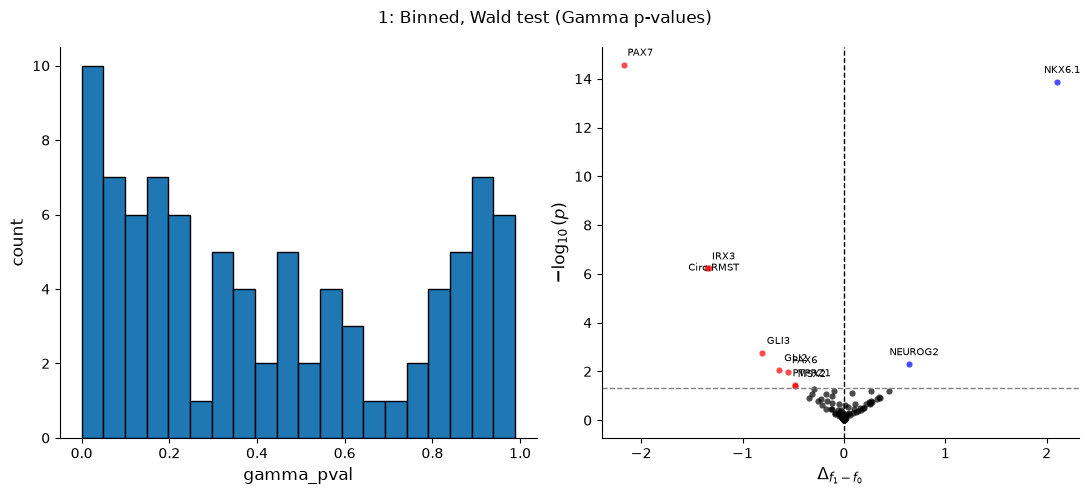

In [6]:
qc_plots(wald_stats, "1: Binned, Wald test (Gamma p-values)", pvalue="gamma_pval", pvalue_adj="gamma_pval_adj");

## 2. Raw cells, parallel-curves test, no slide effects

The binning (contiguous bins) only provides the spline basis and the prediction grid here; the fit uses every cell. `vi_khat` (below ~0.7) and `vi_ess` (above ~0.5) check each gene's approximation against the true posterior.

In [7]:
t0 = time.perf_counter()
dvg.pp.bin_obs(adata, anchor="True", condition="condition", genes=GENES, layer=LAYER, n_bins=50, window_radius=None)
pooled_stats, _, _ = dvg.tl.fit_model(
    adata, dvg.tl.setup_model(adata), n_workers=N_WORKERS, use_binned=False, inference="advi",
    test="parallel", tau=TAU, inplace=False,
)  # fmt: skip
timings["2: curves, cells, ADVI, no slides"] = time.perf_counter() - t0
print(f"{timings['2: curves, cells, ADVI, no slides']:.0f} s")
pooled_stats["vi_trusted"] = (pooled_stats["vi_khat"] < 0.7) & (pooled_stats["vi_ess"] > 0.5)
print(f"{pooled_stats['vi_trusted'].sum()} of {len(pooled_stats)} genes pass the variational diagnostics")
pooled_table = rank_table(pooled_stats, "parallel_pval", "parallel_stat", [*PARALLEL_COLUMNS, "vi_trusted"])
pooled_table.head(25)

Fitting DiffSVG models:   2%|▏         | 2/88 [00:20<11:56,  8.33s/it]/home/lehnerl/miniconda3/envs/pymc_env/lib/python3.14/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
Fitting DiffSVG models: 100%|██████████| 88/88 [06:33<00:00,  4.47s/it]

394 s
85 of 88 genes pass the variational diagnostics



/tmp/ipykernel_57206/1773318310.py:3: UserWarning: 3 of 88 genes fail the variational diagnostics (expected: vi_khat < 0.7 and vi_ess > 0.5), so the approximation does not match the posterior for them: do not read their p-values.
  pooled_stats, _, _ = dvg.tl.fit_model(


,rank,shape_diff,slope_diff,slope_diff_ci_low,slope_diff_ci_high,parallel_stat,parallel_pval,parallel_pval_adj,integral,vi_khat,vi_ess,vi_trusted
gene,,,,,,,,,,,,
PAX7,1,1.771784,-1.049524,-1.102262,-0.999123,6261.889601,0.000000e+00,0.000000e+00,-2.167183,0.207713,0.775775,True
HHIP,2,1.470284,1.016162,0.954145,1.075549,3841.301188,0.000000e+00,0.000000e+00,-0.100362,0.229310,0.784461,True
GLI1,3,1.275424,0.939257,0.879250,0.996867,3141.810411,0.000000e+00,0.000000e+00,0.268184,0.226889,0.782856,True
DBX1,4,1.289429,0.696876,0.609798,0.780463,1936.617573,0.000000e+00,0.000000e+00,-0.173251,0.173907,0.802866,True
DBX2,5,0.934258,0.483018,0.417396,0.545941,1909.282850,0.000000e+00,0.000000e+00,-0.308602,0.242377,0.787491,True
FOXA2,6,1.010627,0.478235,0.437536,0.517036,1878.719035,0.000000e+00,0.000000e+00,-0.004395,0.222257,0.763086,True
AC129492.1,7,1.272180,-1.069983,-1.157454,-0.986010,1563.338684,1.217412e-276,1.530461e-275,-0.117657,0.172541,0.803113,True
PTCH1,8,1.440611,0.501819,0.405175,0.594605,1471.718945,6.243663e-264,6.868029e-263,0.084623,0.147752,0.808582,True
FOS,9,0.970804,-0.615020,-0.685128,-0.547873,1448.503305,1.931668e-240,1.888742e-239,-0.050897,0.237103,0.790818,True


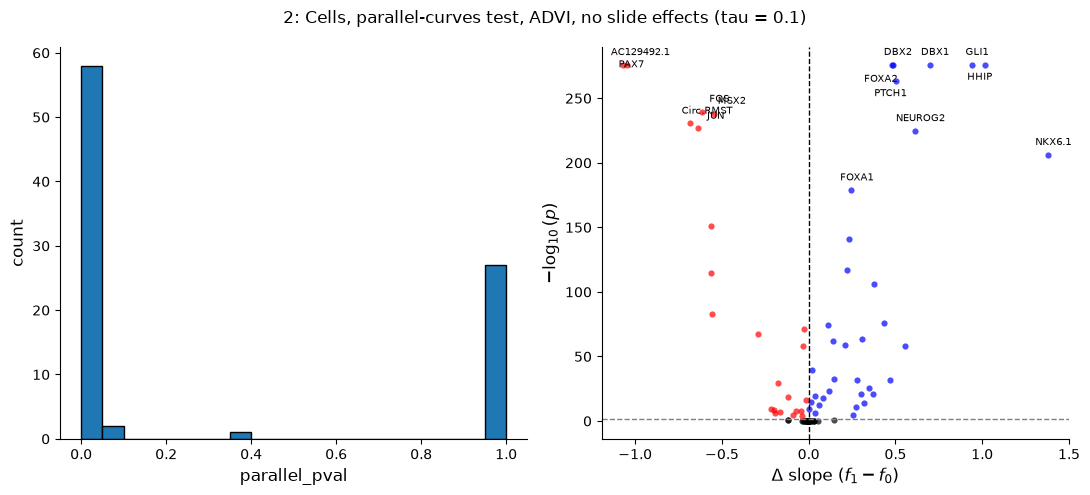

In [8]:
qc_plots(pooled_stats, f"2: Cells, parallel-curves test, ADVI, no slide effects (tau = {TAU})");

## 3. Raw cells, parallel-curves test with empirical-Bayes slide effects

`sample="sample"` adds a random level and a random curve per slide (every slide belongs to one condition; `slide1_A2-2` has no anchor cells and drops out). The two scales of those effects are estimated per gene (`sample_level_sd`, `sample_curve_sd`) and then held fixed while ADVI fits the rest. The p-value uses an F reference with `parallel_df_denominator = n_slides - 2` degrees of freedom; the plotted curves are the population-level ones.

With ~200 parameters per gene the importance-sampling share `vi_ess` is lower even for a good approximation (on simulated slides ~0.45 while matching NUTS), so here `vi_ess > 0.1` together with `vi_khat < 0.7` is the check.

In [9]:
t0 = time.perf_counter()
dvg.pp.bin_obs(
    adata, anchor="True", condition="condition", genes=GENES, layer=LAYER, n_bins=50, window_radius=None, sample="sample"
)
slides_stats, _, _ = dvg.tl.fit_model(
    adata, dvg.tl.setup_model(adata), n_workers=N_WORKERS, use_binned=False, inference="advi",
    slide_scales="empirical_bayes", test="parallel", tau=TAU, inplace=False,
)  # fmt: skip
timings["3: curves, cells, ADVI, EB slides"] = time.perf_counter() - t0
print(f"{timings['3: curves, cells, ADVI, EB slides']:.0f} s")
slides_stats["vi_trusted"] = (slides_stats["vi_khat"] < 0.7) & (slides_stats["vi_ess"] > 0.1)
print(f"{slides_stats['vi_trusted'].sum()} of {len(slides_stats)} genes pass the variational diagnostics")
slides_table = rank_table(
    slides_stats,
    "parallel_pval",
    "parallel_stat",
    [*PARALLEL_COLUMNS, "sample_level_sd", "sample_curve_sd", "parallel_df_denominator", "vi_trusted"],
)
slides_table.head(25)

Fitting DiffSVG models:   7%|▋         | 6/88 [03:36<49:30, 36.23s/it]  /home/lehnerl/miniconda3/envs/pymc_env/lib/python3.14/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
Fitting DiffSVG models: 100%|██████████| 88/88 [33:31<00:00, 22.86s/it]

2012 s
88 of 88 genes pass the variational diagnostics


,rank,shape_diff,slope_diff,slope_diff_ci_low,slope_diff_ci_high,parallel_stat,parallel_pval,parallel_pval_adj,integral,vi_khat,vi_ess,sample_level_sd,sample_curve_sd,parallel_df_denominator,vi_trusted
gene,,,,,,,,,,,,,,,
HHIP,1,1.383929,0.910924,0.638617,1.184634,138.587987,0.000101,0.008260,-0.085208,0.097706,0.404064,0.110450,0.277793,14,True
FOXA2,2,0.812904,0.398578,0.182974,0.615921,151.363630,0.000188,0.008260,0.006869,0.090689,0.365969,0.044484,0.220540,14,True
GLI1,3,1.172933,0.832966,0.587908,1.079224,114.281428,0.000407,0.009571,0.276354,0.148722,0.429852,0.096921,0.247894,14,True
PAX7,4,1.485806,-0.905374,-1.289125,-0.512398,93.094506,0.000435,0.009571,-2.115028,0.231869,0.227903,0.207072,0.407721,14,True
NEUROG2,5,1.084901,0.370091,0.060921,0.679444,66.907708,0.002818,0.049595,0.635596,0.211078,0.441419,0.224709,0.313438,14,True
PTCH1,6,1.236055,0.180200,-0.235084,0.597428,46.780245,0.008887,0.118678,0.145253,0.160079,0.370632,0.337614,0.434457,14,True
MSX2,7,0.608092,-0.538885,-0.653635,-0.424896,116.864504,0.009440,0.118678,-0.449460,-0.009082,0.495972,0.146333,0.110829,14,True
FOXA1,8,0.404139,0.193341,0.039602,0.348744,85.322031,0.025010,0.275106,-0.019739,0.241804,0.251561,0.029723,0.158258,14,True
DBX2,9,0.974715,0.632143,0.321033,0.946719,39.806060,0.030811,0.301259,-0.320879,0.172383,0.364833,0.161891,0.321361,14,True


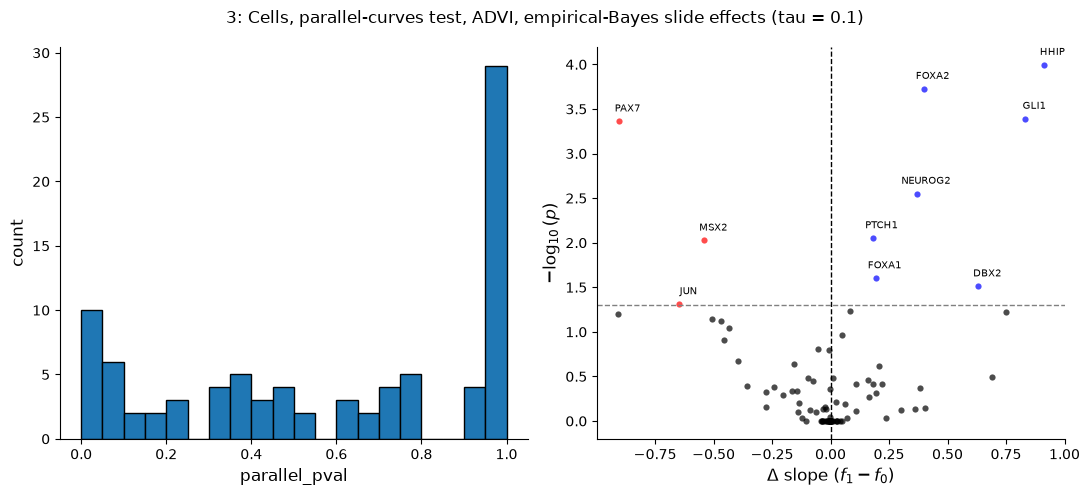

In [10]:
qc_plots(slides_stats, f"3: Cells, parallel-curves test, ADVI, empirical-Bayes slide effects (tau = {TAU})");

In [11]:
slides_stats.loc[~slides_stats["vi_trusted"], ["vi_khat", "vi_ess", "sample_level_sd", "sample_curve_sd", "parallel_pval"]]

,vi_khat,vi_ess,sample_level_sd,sample_curve_sd,parallel_pval
gene,,,,,


## Comparison

How many genes each approach calls, how much the rankings agree (Spearman correlation of the ranks, overlap of the top 20), and how the parallel-curves test's effect sizes and significance change once slides are modelled.

In [12]:
calls = pd.DataFrame(
    {
        "p < 0.05": {
            "1: Wald (Gamma)": int((wald_stats["gamma_pval"] < 0.05).sum()),
            "2: curves, no slides": int((pooled_stats["parallel_pval"] < 0.05).sum()),
            "3: curves, EB slides": int((slides_stats["parallel_pval"] < 0.05).sum()),
        },
        "BH-adjusted < 0.05": {
            "1: Wald (Gamma)": int((wald_stats["gamma_pval_adj"] < 0.05).sum()),
            "2: curves, no slides": int((pooled_stats["parallel_pval_adj"] < 0.05).sum()),
            "3: curves, EB slides": int((slides_stats["parallel_pval_adj"] < 0.05).sum()),
        },
    }
)
display(calls)

ranks = pd.DataFrame(
    {
        "1: Wald (Gamma)": wald_table["rank"],
        "2: curves, no slides": pooled_table["rank"],
        "3: curves, EB slides": slides_table["rank"],
    }
)
print("Spearman correlation of the ranks")
display(ranks.corr(method="spearman").round(3))

top = {name: set(ranks[name].nsmallest(20).index) for name in ranks}
print("Overlap of the top 20 genes")
display(pd.DataFrame({a: {b: len(top[a] & top[b]) for b in top} for a in top}))

pd.Series(timings, name="seconds").round(0).to_frame()

,p < 0.05,BH-adjusted < 0.05
1: Wald (Gamma),10,5
"2: curves, no slides",58,58
"3: curves, EB slides",10,5


Spearman correlation of the ranks


,1: Wald (Gamma),"2: curves, no slides","3: curves, EB slides"
1: Wald (Gamma),1.000,0.866,0.802
"2: curves, no slides",0.866,1.000,0.921
"3: curves, EB slides",0.802,0.921,1.000


Overlap of the top 20 genes


,1: Wald (Gamma),"2: curves, no slides","3: curves, EB slides"
1: Wald (Gamma),20,13,12
"2: curves, no slides",13,20,17
"3: curves, EB slides",12,17,20


,seconds
"1: Wald, binned, NUTS",204.0
"2: curves, cells, ADVI, no slides",394.0
"3: curves, cells, ADVI, EB slides",2012.0


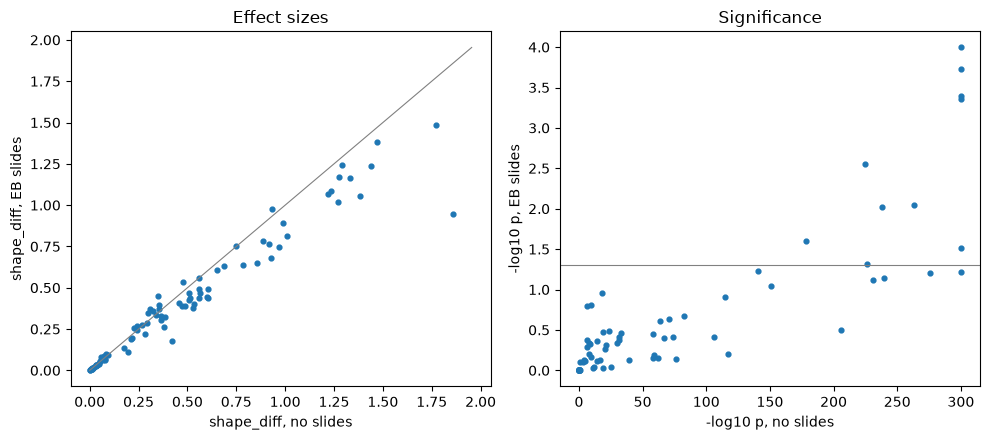

In [13]:
genes = pooled_stats.index
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
axes[0].scatter(pooled_stats["shape_diff"], slides_stats.loc[genes, "shape_diff"], s=12)
lim = float(max(pooled_stats["shape_diff"].max(), slides_stats["shape_diff"].max())) * 1.05
axes[0].plot([0, lim], [0, lim], color="grey", lw=0.8)
axes[0].set(xlabel="shape_diff, no slides", ylabel="shape_diff, EB slides", title="Effect sizes")
floor = 1e-300
axes[1].scatter(
    -np.log10(pooled_stats["parallel_pval"].clip(lower=floor)),
    -np.log10(slides_stats.loc[genes, "parallel_pval"].clip(lower=floor)),
    s=12,
)
axes[1].axhline(-np.log10(0.05), color="grey", lw=0.8)
axes[1].set(xlabel="-log10 p, no slides", ylabel="-log10 p, EB slides", title="Significance")
fig.tight_layout()

## 4. Clustering the fitted curves

`fit_model` keeps the posterior means of the spline coefficients, and `dvg.tl.cluster_curves` runs k-means on them, so genes group by the shape of their curves. `dvg.pl.plot_cluster_curves` then draws one panel per cluster with each gene's curve in its own colour.

**This section only needs the data and settings cells above**, not parts 1-3. Its fit is the slide model of part 3 on per-slide contiguous bins instead of single cells. Weighted bins have the same likelihood as the cells, so the two agree (`parallel_stat`, bins vs. part 3: HHIP 139.5 / 138.6, FOXA2 152.7 / 151.4, GLI1 117.2 / 114.3, PAX7 92.3 / 93.1) at about a twelfth of the cost: under 3 min with 4 workers. Part 3 calls `fit_model(..., inplace=False)`, which returns the coefficients as `curves["beta"]` and `curves["beta_1"]`; here `inplace=True` writes them to `adata.varm`, where the clustering reads them.

In [14]:
from sklearn.metrics import adjusted_rand_score

t0 = time.perf_counter()
dvg.pp.bin_obs(
    adata, anchor="True", condition="condition", genes=GENES, layer=LAYER, n_bins=50, window_radius=None, sample="sample"
)
dvg.tl.fit_model(
    adata, dvg.tl.setup_model(adata), n_workers=N_WORKERS, use_binned=True, inference="advi", test="parallel", tau=TAU
)
timings["4: curves, bins, ADVI, EB slides"] = time.perf_counter() - t0
print(f"{timings['4: curves, bins, ADVI, EB slides']:.0f} s")
fit_stats = adata.varm["dsvg_stats"].loc[GENES]
print(f"{((fit_stats['vi_khat'] < 0.7) & (fit_stats['vi_ess'] > 0.1)).sum()} of {len(fit_stats)} genes pass the variational diagnostics")
print(f"p < 0.05: {(fit_stats['parallel_pval'] < 0.05).sum()}, BH-adjusted < 0.05: {(fit_stats['parallel_pval_adj'] < 0.05).sum()}")
{name: adata.varm[f"dsvg_coefs_{name}"].shape for name in ("beta", "beta_1")}

Fitting DiffSVG models: 100%|██████████| 88/88 [03:11<00:00,  2.18s/it]

192 s
88 of 88 genes pass the variational diagnostics
p < 0.05: 11, BH-adjusted < 0.05: 5


{'beta': (88, 10), 'beta_1': (88, 10)}

### Choosing `k`

The silhouette (higher is better) over `k`, for both kinds of coefficients. It favours small `k`, where a large flat cluster stands against a few strong patterns, so it is a guide and does not settle the choice. `k = 5` keeps patterns apart that `k = 3` merges; the last cell of this section checks how stable that is.

In [15]:
N_CLUSTERS = 5


def cluster_table(key):
    """One row per cluster: its size, how many of its genes the parallel-curves test flags, and the genes."""
    labels = adata.var[key].dropna()
    return pd.DataFrame(
        {
            cluster: {
                "n": len(genes),
                "p < 0.05": int((fit_stats.loc[genes, "parallel_pval"] < 0.05).sum()),
                "BH < 0.05": int((fit_stats.loc[genes, "parallel_pval_adj"] < 0.05).sum()),
                "median shape_diff": round(float(fit_stats.loc[genes, "shape_diff"].median()), 2),
                "genes": ", ".join(genes),
            }
            for cluster, genes in ((c, list(labels.index[labels == c])) for c in labels.cat.categories)
        }
    ).T


silhouettes = {}
for by in ("average", "interaction"):
    for k in range(2, 9):
        dvg.tl.cluster_curves(adata, by=by, n_clusters=k, key_added="scan")
        silhouettes[by, k] = adata.uns["scan"]["silhouette"]
del adata.var["scan"], adata.uns["scan"]
pd.Series(silhouettes).unstack(0).round(3).rename_axis("k")

,average,interaction
k,,
2,0.427,0.343
3,0.438,0.469
4,0.407,0.330
5,0.430,0.325
6,0.458,0.337
7,0.446,0.351
8,0.448,0.341


### Combined: the curve averaged over both conditions

`by="average"` clusters `beta + beta_1 / 2`, the coefficients of the mean of the two condition curves, weighting both conditions equally. `beta` alone would not do: with the 0/1 condition coding, `y = alpha + B beta + gamma c + c B beta_1`, so `beta` is the curve of condition 0 (here Ctrl) and does not see what happens under SHH. A fit that ignores the condition is another option: `fit_profiles` on data binned with `condition=None`, then `by="profile"` (no slide effects there).

,n,p < 0.05,BH < 0.05,median shape_diff,genes
0,51,1,0,0.09,"AIF1, ALDH1L1, AQP4, ARC, ARG1, BCL11B, BMP4, ..."
1,22,4,0,0.48,"AC129492.1, AGO2, Circ.CDR1, CUL3, DBX1, DBX2,..."
2,7,5,4,0.94,"FOXA1, FOXA2, GLI1, HHIP, NEUROG2, NKX6.1, SHH"
3,5,1,1,0.75,"GLI3, IRX3, PAX6, PAX7, PTPRZ1"
4,3,0,0,0.63,"Circ.RMST, STMN2, TUBB3"


:Layout
   .Overlay.I   :Overlay
      .Curve.AIF1             :Curve   [distance]   (centred expression)
      .Curve.ALDH1L1          :Curve   [distance]   (centred expression)
      .Curve.AQP4             :Curve   [distance]   (centred expression)
      .Curve.ARC              :Curve   [distance]   (centred expression)
      .Curve.ARG1             :Curve   [distance]   (centred expression)
      .Curve.BCL11B           :Curve   [distance]   (centred expression)
      .Curve.BMP4             :Curve   [distance]   (centred expression)
      .Curve.CALB1            :Curve   [distance]   (centred expression)
      .Curve.CDR1             :Curve   [distance]   (centred expression)
      .Curve.CHAT             :Curve   [distance]   (centred expression)
      .Curve.CHPF2            :Curve   [distance]   (centred expression)
      .Curve.CUX2             :Curve   [distance]   (centred expression)
      .Curve.DLX2             :Curve   [distance]   (centred expression)
      .Curve.EOMES            :Curve   [distance]   (centred expression)
      .Curve.EYA4             :Curve   [distance]   (centred expression)
      .Curve.FOS              :Curve   [distance]   (centred expression)
      .Curve.FOSB             :Curve   [distance]   (centred expression)
      .Curve.FOSL2            :Curve   [distance]   (centred expression)
      .Curve.FOXO6            :Curve   [distance]   (centred expression)
      .Curve.FZD10            :Curve   [distance]   (centred expression)
      .Curve.GRID2            :Curve   [distance]   (centred expression)
      .Curve.HES6             :Curve   [distance]   (centred expression)
      .Curve.HEY1             :Curve   [distance]   (centred expression)
      .Curve.HOPX             :Curve   [distance]   (centred expression)
      .Curve.HPRT1            :Curve   [distance]   (centred expression)
      .Curve.ISL1             :Curve   [distance]   (centred expression)
      .Curve.JUNB             :Curve   [distance]   (centred expression)
      .Curve.KLF4             :Curve   [distance]   (centred expression)
      .Curve.LUM              :Curve   [distance]   (centred expression)
      .Curve.MNX1             :Curve   [distance]   (centred expression)
      .Curve.MOG              :Curve   [distance]   (centred expression)
      .Curve.MSX2             :Curve   [distance]   (centred expression)
      .Curve.MYRIP            :Curve   [distance]   (centred expression)
      .Curve.NKX2_full_stop_1 :Curve   [distance]   (centred expression)
      .Curve.NKX2_full_stop_2 :Curve   [distance]   (centred expression)
      .Curve.NKX6_full_stop_2 :Curve   [distance]   (centred expression)
      .Curve.NR4A2            :Curve   [distance]   (centred expression)
      .Curve.NR4A3            :Curve   [distance]   (centred expression)
      .Curve.OLIG1            :Curve   [distance]   (centred expression)
      .Curve.OLIG2            :Curve   [distance]   (centred expression)
      .Curve.OTP              :Curve   [distance]   (centred expression)
      .Curve.OTX2             :Curve   [distance]   (centred expression)
      .Curve.PER2             :Curve   [distance]   (centred expression)
      .Curve.PER3             :Curve   [distance]   (centred expression)
      .Curve.POLR1B           :Curve   [distance]   (centred expression)
      .Curve.SIX6             :Curve   [distance]   (centred expression)
      .Curve.SNCA             :Curve   [distance]   (centred expression)
      .Curve.TBR1             :Curve   [distance]   (centred expression)
      .Curve.TUBB1            :Curve   [distance]   (centred expression)
      .Curve.FOXG1            :Curve   [distance]   (centred expression)
      .Curve.TREM2            :Curve   [distance]   (centred expression)
   .Overlay.II  :Overlay
      .Curve.AC129492_full_stop_1 :Curve   [distance]   (centred expression)
      .Curve.AGO2                 :Curve   [distance]   (centred expression)
      .Curve.Circ_full_stop_CDR1  :Curve   [distance]   (centred 
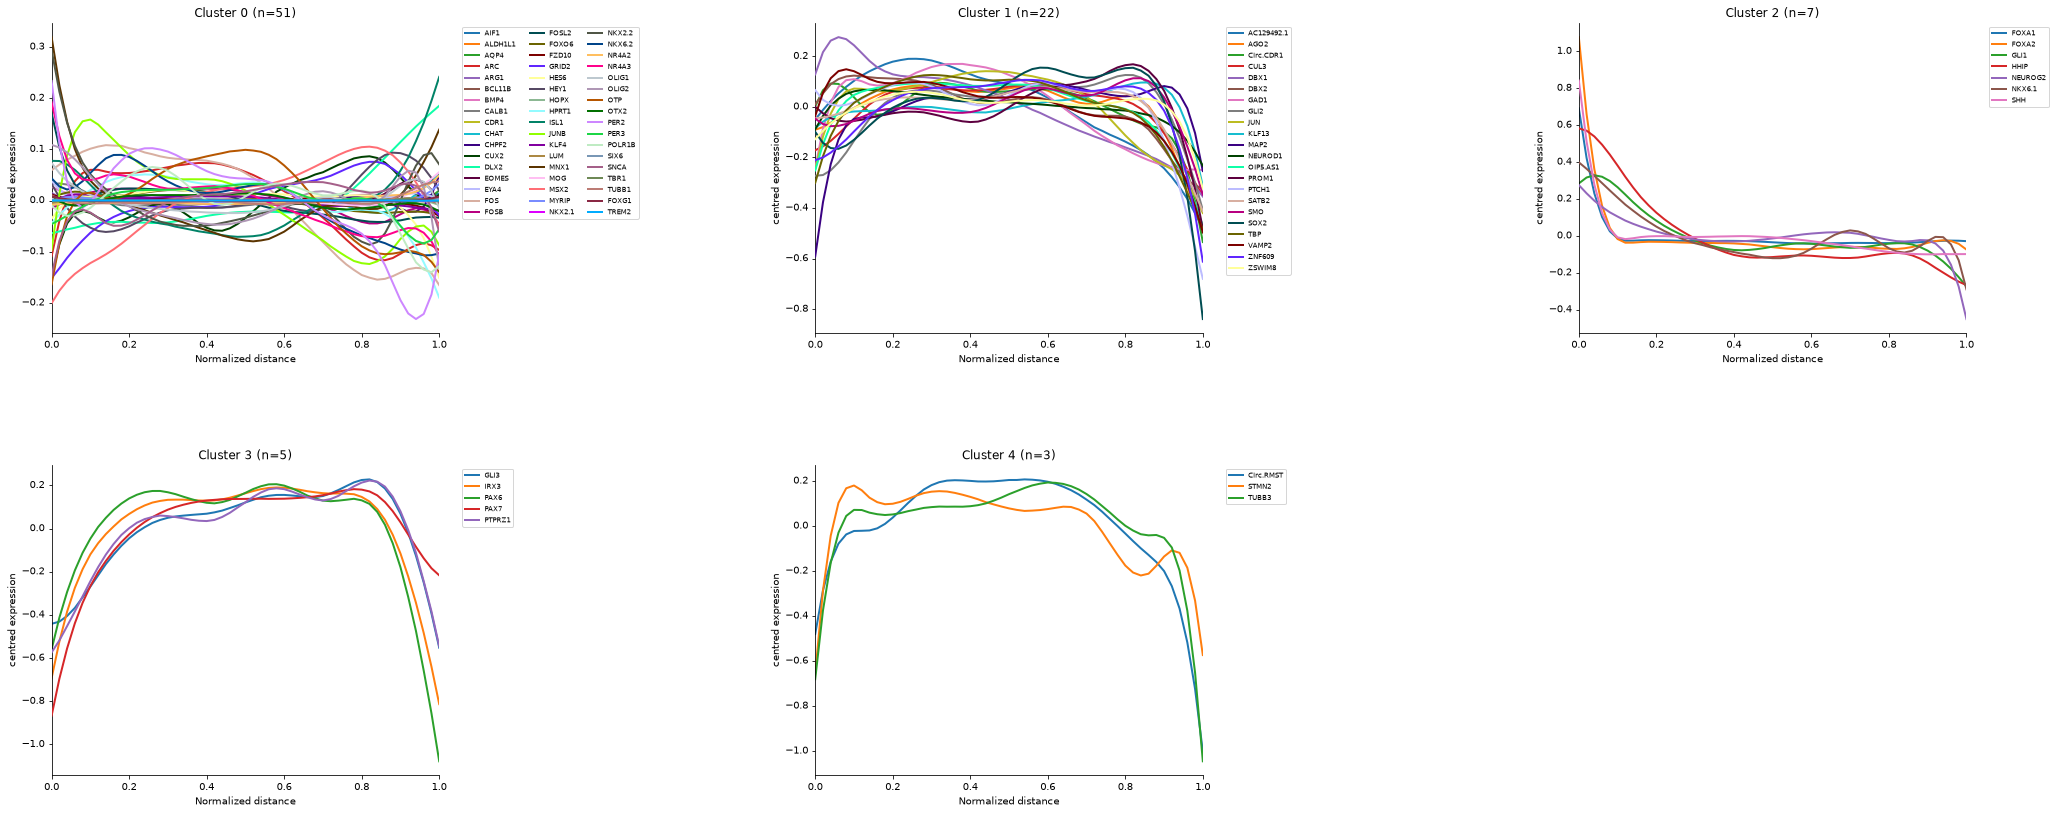

In [16]:
dvg.tl.cluster_curves(adata, by="average", n_clusters=N_CLUSTERS)
display(cluster_table("dsvg_cluster_average"))
dvg.pl.plot_cluster_curves(adata, "dsvg_cluster_average")

### Split by condition: the interaction coefficients

`by="interaction"` clusters `beta_1`, the shape of the difference curve `f1 - f0` (SHH minus Ctrl). The level difference is a separate coefficient, so it plays no part. By default the plot shows the difference curves, centred, since those are what the clustering compared. The amplitude counts, so genes without a difference collect in a flat cluster.

,n,p < 0.05,BH < 0.05,median shape_diff,genes
0,45,0,0,0.07,"AIF1, ALDH1L1, AQP4, ARC, ARG1, BCL11B, BMP4, ..."
1,22,0,0,0.48,"AGO2, CUL3, CUX2, GAD1, GLI2, GLI3, IRX3, KLF1..."
2,8,6,3,1.12,"DBX1, DBX2, GLI1, HHIP, NEUROG2, NKX6.1, PROM1..."
3,7,3,1,1.02,"AC129492.1, Circ.RMST, FOS, JUN, JUNB, MSX2, PAX7"
4,6,2,1,0.37,"Circ.CDR1, FOXA1, FOXA2, MNX1, PER2, SHH"


:Layout
   .Overlay.I   :Overlay
      .Curve.AIF1             :Curve   [distance]   (centred expression)
      .Curve.ALDH1L1          :Curve   [distance]   (centred expression)
      .Curve.AQP4             :Curve   [distance]   (centred expression)
      .Curve.ARC              :Curve   [distance]   (centred expression)
      .Curve.ARG1             :Curve   [distance]   (centred expression)
      .Curve.BCL11B           :Curve   [distance]   (centred expression)
      .Curve.BMP4             :Curve   [distance]   (centred expression)
      .Curve.CALB1            :Curve   [distance]   (centred expression)
      .Curve.CDR1             :Curve   [distance]   (centred expression)
      .Curve.CHAT             :Curve   [distance]   (centred expression)
      .Curve.CHPF2            :Curve   [distance]   (centred expression)
      .Curve.DLX2             :Curve   [distance]   (centred expression)
      .Curve.EOMES            :Curve   [distance]   (centred expression)
      .Curve.EYA4             :Curve   [distance]   (centred expression)
      .Curve.FOSB             :Curve   [distance]   (centred expression)
      .Curve.FOSL2            :Curve   [distance]   (centred expression)
      .Curve.FOXO6            :Curve   [distance]   (centred expression)
      .Curve.FZD10            :Curve   [distance]   (centred expression)
      .Curve.GRID2            :Curve   [distance]   (centred expression)
      .Curve.HES6             :Curve   [distance]   (centred expression)
      .Curve.HEY1             :Curve   [distance]   (centred expression)
      .Curve.HOPX             :Curve   [distance]   (centred expression)
      .Curve.HPRT1            :Curve   [distance]   (centred expression)
      .Curve.ISL1             :Curve   [distance]   (centred expression)
      .Curve.KLF4             :Curve   [distance]   (centred expression)
      .Curve.LUM              :Curve   [distance]   (centred expression)
      .Curve.MOG              :Curve   [distance]   (centred expression)
      .Curve.MYRIP            :Curve   [distance]   (centred expression)
      .Curve.NEUROD1          :Curve   [distance]   (centred expression)
      .Curve.NKX2_full_stop_1 :Curve   [distance]   (centred expression)
      .Curve.NKX2_full_stop_2 :Curve   [distance]   (centred expression)
      .Curve.NR4A2            :Curve   [distance]   (centred expression)
      .Curve.NR4A3            :Curve   [distance]   (centred expression)
      .Curve.OLIG1            :Curve   [distance]   (centred expression)
      .Curve.OLIG2            :Curve   [distance]   (centred expression)
      .Curve.OTX2             :Curve   [distance]   (centred expression)
      .Curve.PER3             :Curve   [distance]   (centred expression)
      .Curve.SIX6             :Curve   [distance]   (centred expression)
      .Curve.SNCA             :Curve   [distance]   (centred expression)
      .Curve.STMN2            :Curve   [distance]   (centred expression)
      .Curve.TBR1             :Curve   [distance]   (centred expression)
      .Curve.TUBB1            :Curve   [distance]   (centred expression)
      .Curve.ZSWIM8           :Curve   [distance]   (centred expression)
      .Curve.FOXG1            :Curve   [distance]   (centred expression)
      .Curve.TREM2            :Curve   [distance]   (centred expression)
   .Overlay.II  :Overlay
      .Curve.AGO2               :Curve   [distance]   (centred expression)
      .Curve.CUL3               :Curve   [distance]   (centred expression)
      .Curve.CUX2               :Curve   [distance]   (centred expression)
      .Curve.GAD1               :Curve   [distance]   (centred expression)
      .Curve.GLI2               :Curve   [distance]   (centred expression)
      .Curve.GLI3               :Curve   [distance]   (centred expression)
      .Curve.IRX3               :Curve   [distance]   (centred expression)
      .Curve.KLF13              :Curve   [distance]   (centred expression)
      .Curve.MAP2               :Curve   [distance]   (ce
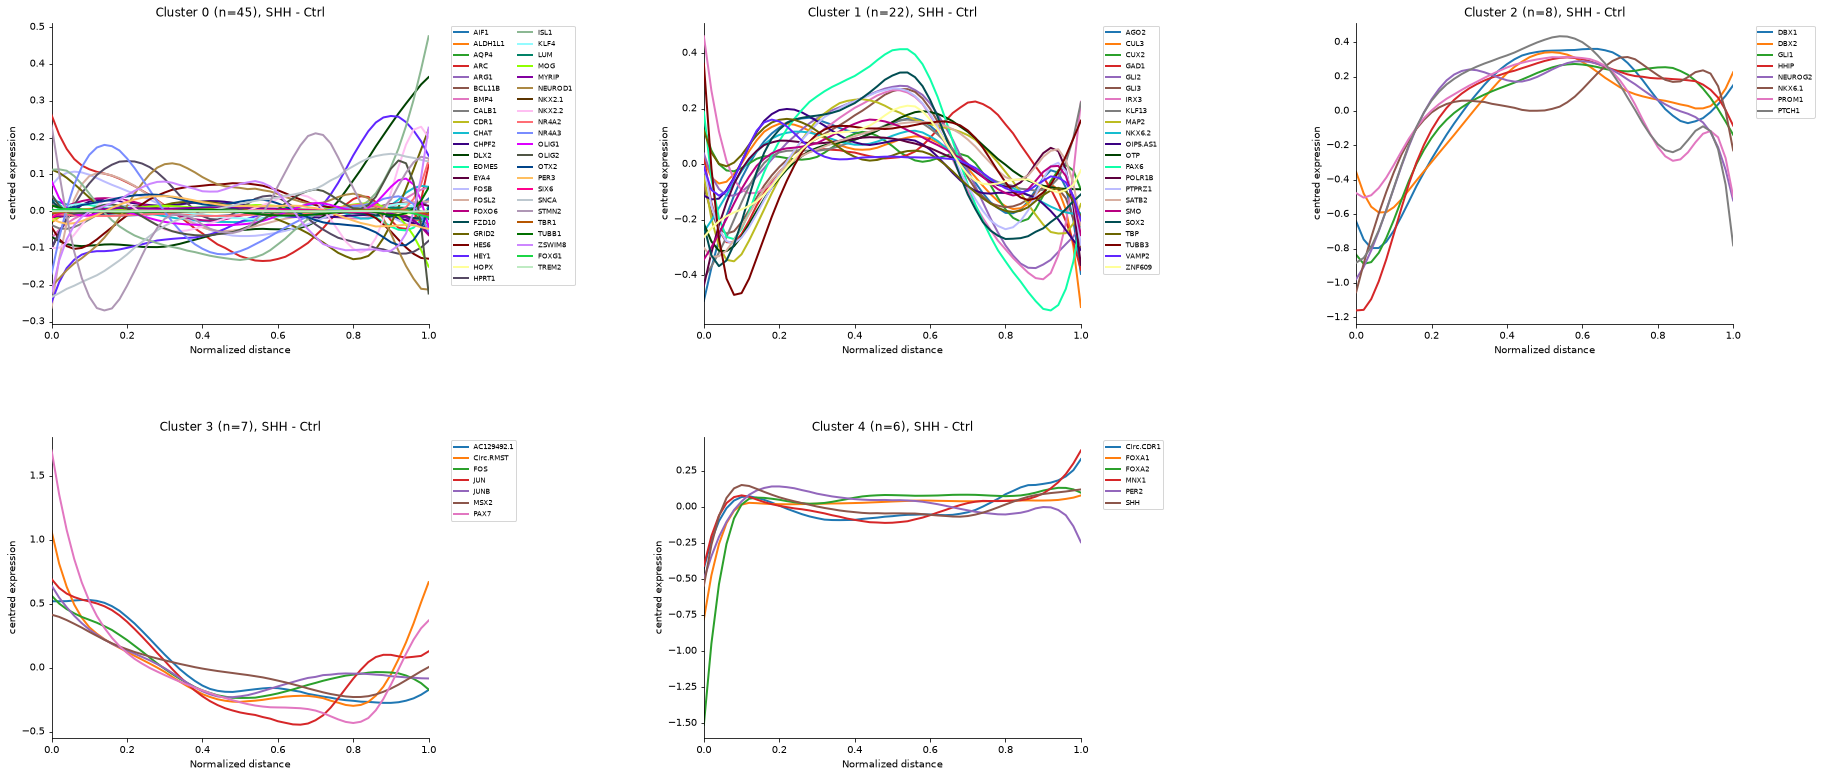

In [17]:
dvg.tl.cluster_curves(adata, by="interaction", n_clusters=N_CLUSTERS)
display(cluster_table("dsvg_cluster_interaction"))
dvg.pl.plot_cluster_curves(adata, "dsvg_cluster_interaction")

`curves="conditions"` draws the same clusters split by condition: one row per cluster, Ctrl left, SHH right, in a shared y-range and with the same gene colours. Each gene is centred over both conditions together, so the gap between them stays visible. The three clusters with a clear pattern:

:Layout
   .Overlay.I   :Overlay
      .Curve.DBX1             :Curve   [distance]   (centred expression)
      .Curve.DBX2             :Curve   [distance]   (centred expression)
      .Curve.GLI1             :Curve   [distance]   (centred expression)
      .Curve.HHIP             :Curve   [distance]   (centred expression)
      .Curve.NEUROG2          :Curve   [distance]   (centred expression)
      .Curve.NKX6_full_stop_1 :Curve   [distance]   (centred expression)
      .Curve.PROM1            :Curve   [distance]   (centred expression)
      .Curve.PTCH1            :Curve   [distance]   (centred expression)
   .Overlay.II  :Overlay
      .Curve.DBX1             :Curve   [distance]   (centred expression)
      .Curve.DBX2             :Curve   [distance]   (centred expression)
      .Curve.GLI1             :Curve   [distance]   (centred expression)
      .Curve.HHIP             :Curve   [distance]   (centred expression)
      .Curve.NEUROG2          :Curve   [distance]   (centred expression)
      .Curve.NKX6_full_stop_1 :Curve   [distance]   (centred expression)
      .Curve.PROM1            :Curve   [distance]   (centred expression)
      .Curve.PTCH1            :Curve   [distance]   (centred expression)
   .Overlay.III :Overlay
      .Curve.AC129492_full_stop_1 :Curve   [distance]   (centred expression)
      .Curve.Circ_full_stop_RMST  :Curve   [distance]   (centred expression)
      .Curve.FOS                  :Curve   [distance]   (centred expression)
      .Curve.JUN                  :Curve   [distance]   (centred expression)
      .Curve.JUNB                 :Curve   [distance]   (centred expression)
      .Curve.MSX2                 :Curve   [distance]   (centred expression)
      .Curve.PAX7                 :Curve   [distance]   (centred expression)
   .Overlay.IV  :Overlay
      .Curve.AC129492_full_stop_1 :Curve   [distance]   (centred expression)
      .Curve.Circ_full_stop_RMST  :Curve   [distance]   (centred expression)
      .Curve.FOS                  :Curve   [distance]   (centred expression)
      .Curve.JUN                  :Curve   [distance]   (centred expression)
      .Curve.JUNB                 :Curve   [distance]   (centred expression)
      .Curve.MSX2                 :Curve   [distance]   (centred expression)
      .Curve.PAX7                 :Curve   [distance]   (centred expression)
   .Overlay.V   :Overlay
      .Curve.Circ_full_stop_CDR1 :Curve   [distance]   (centred expression)
      .Curve.FOXA1               :Curve   [distance]   (centred expression)
      .Curve.FOXA2               :Curve   [distance]   (centred expression)
      .Curve.MNX1                :Curve   [distance]   (centred expression)
      .Curve.PER2                :Curve   [distance]   (centred expression)
      .Curve.SHH                 :Curve   [distance]   (centred expression)
   .Overlay.VI  :Overlay
      .Curve.Circ_full_stop_CDR1 :Curve   [distance]   (centred expression)
      .Curve.FOXA1               :Curve   [distance]   (centred expression)
      .Curve.FOXA2               :Curve   [distance]   (centred expression)
      .Curve.MNX1                :Curve   [distance]   (centred expression)
      .Curve.PER2                :Curve   [distance]   (centred expression)
      .Curve.SHH                 :Curve   [distance]   (centred expression)
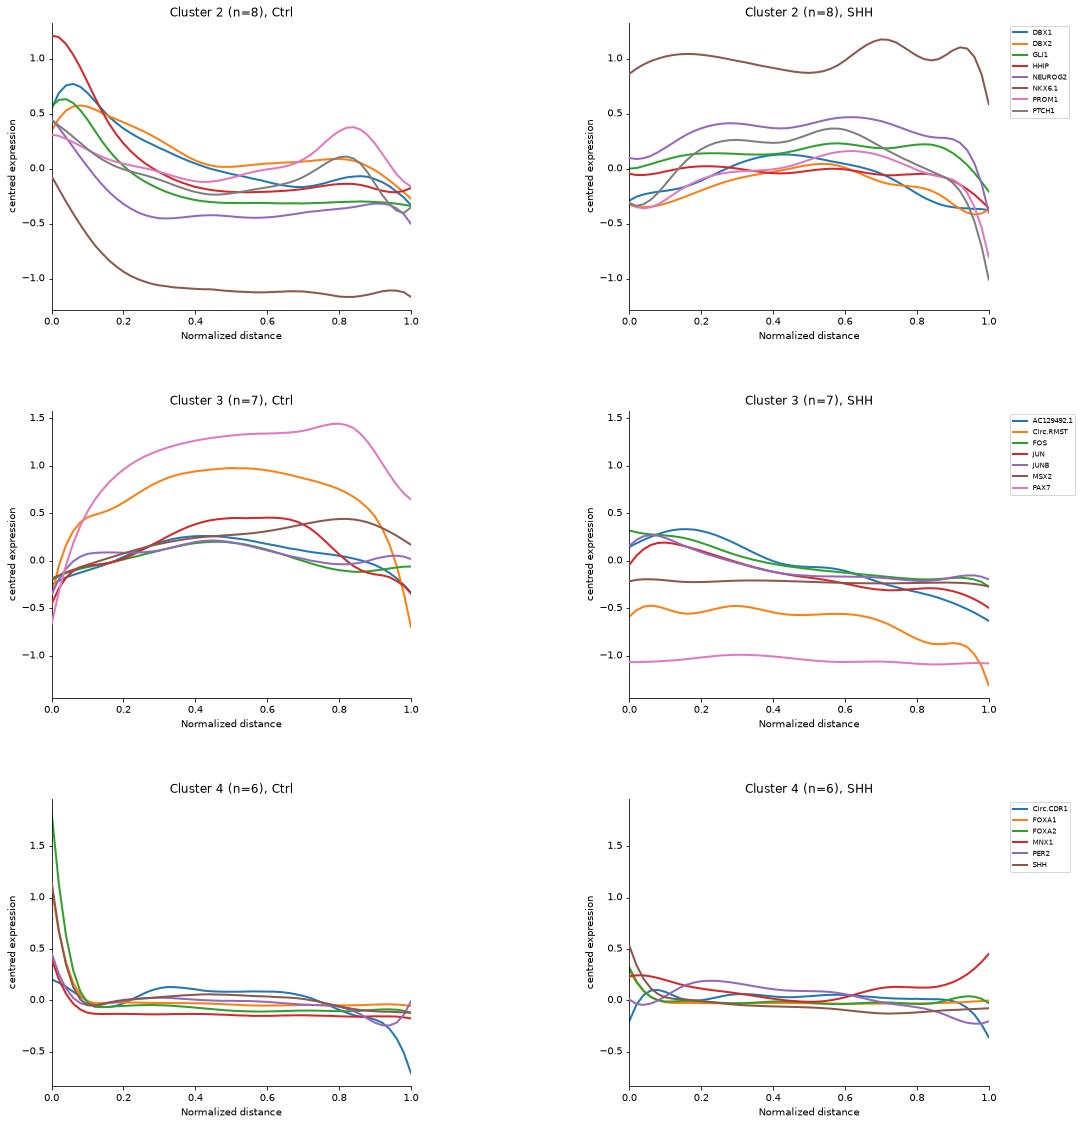

In [18]:
patterned = adata.var["dsvg_cluster_interaction"].cat.categories[2:]
dvg.pl.plot_cluster_curves(adata, "dsvg_cluster_interaction", curves="conditions", clusters=list(patterned))

### How much to trust the clusters

Two checks. **Seeds:** the agreement between k-means runs from 20 different seeds, for both clusterings, and whether the genes of the patterned interaction clusters stay together. **Overlap:** whether the two clusterings say different things, from their adjusted Rand index and the per-gene correlation between the coefficients of the combined curve and `beta_1`. The clusters also share their source with the test (`beta_1`), so finding the flagged genes in the patterned clusters describes them and does not confirm them.

The combined coefficients and `beta_1` are close to mirror images for the significant genes and nearly unrelated for the others. A mirror image is what a nearly flat curve in one condition produces: the combined curve is then half the other condition's curve, and the difference curve is that same curve, up to its sign. So where the signal is, the two clusterings partly repeat each other, which fits their moderate adjusted Rand index.

In [19]:
def seed_runs(by):
    return [
        dvg.tl.cluster_curves(adata, by=by, n_clusters=N_CLUSTERS, inplace=False, random_state=seed).astype(str)
        for seed in range(20)
    ]


runs = {by: seed_runs(by) for by in ("average", "interaction")}
for by, by_runs in runs.items():
    agreement = [adjusted_rand_score(by_runs[0], run) for run in by_runs[1:]]
    print(f"Seeds, {by}, adjusted Rand index against the first run: median {np.median(agreement):.2f}, min {np.min(agreement):.2f}")

labels = adata.var["dsvg_cluster_interaction"].astype(str)
together = {
    cluster: float(np.mean([len(set(run[genes])) == 1 for run in runs["interaction"]]))
    for cluster, genes in ((c, labels.index[labels == c]) for c in patterned)
}
print("Share of seeds keeping each patterned interaction cluster whole:", {c: round(v, 2) for c, v in together.items()})

overlap = adjusted_rand_score(adata.var["dsvg_cluster_average"].astype(str), labels)
print(f"Combined vs. interaction clusters, adjusted Rand index: {overlap:.2f}")


def centred(table):
    return table.sub(table.mean(axis=1), axis=0).loc[GENES].to_numpy()


beta, beta_1 = centred(adata.varm["dsvg_coefs_beta"]), centred(adata.varm["dsvg_coefs_beta_1"])
mirror = pd.Series([np.corrcoef(a, b)[0, 1] for a, b in zip(beta + beta_1 / 2, beta_1, strict=True)], index=GENES)
flagged = fit_stats["parallel_pval_adj"] < 0.05
print(f"Median correlation of the combined coefficients and beta_1: BH-significant genes {mirror[flagged].median():.2f}, "
      f"genes with p >= 0.05 {mirror[fit_stats['parallel_pval'] >= 0.05].median():.2f}")

Seeds, average, adjusted Rand index against the first run: median 0.96, min 0.88
Seeds, interaction, adjusted Rand index against the first run: median 0.98, min 0.86
Share of seeds keeping each patterned interaction cluster whole: {'2': 0.7, '3': 1.0, '4': 0.9}
Combined vs. interaction clusters, adjusted Rand index: 0.51
Median correlation of the combined coefficients and beta_1: BH-significant genes -0.92, genes with p >= 0.05 0.15
